# 06 · A full-URL dataset, audited for leaks

Stage 2 trains a deep model on **whole URLs**, paths included, so it can catch what v1 can't: phishing pages planted on hacked legit sites (`real-winery.com/wp-includes/...`).

Notebooks 01 to 04 taught the main risk: a model learns *how each class was collected* before it learns anything about phishing. PhiUSIIL leaked through the scheme, the path, and subdomains. So this notebook builds the data, then **tries to catch it leaking** before any deep model sees it.

| class | source | why |
|---|---|---|
| phishing | Phishing.Database ACTIVE list (~790k URLs, GitHub) | most have paths; includes hacked legit sites |
| legit | Common Crawl index (`scripts/collect_commoncrawl.py`) and site sitemaps (`scripts/collect_sitemaps.py`) | real pages with paths from real sites, head and long tail |

Nothing from the notebook 03 to 05 benchmark's domains is allowed in, so the benchmark still measures generalization.

**Safety:** phishing URLs are handled as text only and displayed defanged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

from phishdetect.data import PROJECT_ROOT
from phishdetect.features import split_host
from phishdetect.benchmark import defang
from phishdetect.fullurl import (load_phishing_database, load_legit, benchmark_domains,
                                 normalize_full_url, cap_per_domain, shallow_stats)

pd.set_option("display.max_colwidth", 100)
RANDOM_STATE = 42
PHISH_PER_DOMAIN = 5     # one phishing campaign often spins up hundreds of URLs on one domain
LEGIT_PER_DOMAIN = 15    # the collector already caps at 15

## 1. Load both sources

In [2]:
%%time
phish_raw = load_phishing_database()
legit_raw = load_legit()   # Common Crawl + sitemaps, whatever has been collected
print(f"phishing: {len(phish_raw):,} URLs   legit: {len(legit_raw):,} URLs")
legit_raw["source"].value_counts()

phishing: 789,052 URLs   legit: 35,043 URLs
CPU times: user 347 ms, sys: 45.5 ms, total: 392 ms
Wall time: 424 ms


source
sitemap        30556
commoncrawl     4487
Name: count, dtype: int64

## 2. Remove benchmark domains, and any overlap between the classes
A domain on the phishing list is never used as a legit example. That's usually a hacked site, and its "legit" pages are untrustworthy. The collector already skipped these; this checks again.

In [3]:
%%time
for d in (phish_raw, legit_raw):
    d["registered"] = d["url"].map(lambda u: split_host(u)["registered"])

bench = benchmark_domains(RANDOM_STATE)
phish_domains = set(phish_raw["registered"])
before = len(phish_raw), len(legit_raw)
phish = phish_raw[~phish_raw["registered"].isin(bench)]
legit = legit_raw[~legit_raw["registered"].isin(bench | phish_domains)]
print(f"benchmark domains: {len(bench):,}")
print(f"phishing kept {len(phish):,} of {before[0]:,}; legit kept {len(legit):,} of {before[1]:,}")

benchmark domains: 5,639
phishing kept 782,891 of 789,052; legit kept 35,043 of 35,043
CPU times: user 3.71 s, sys: 115 ms, total: 3.83 s
Wall time: 3.89 s


## 3. Cap URLs per domain and balance the classes
Without a cap, a few phishing kits with thousands of URLs each would dominate, and the model would just memorize them. The classes are then balanced 50/50. The real-world rarity of phishing is handled later by the threshold, as in notebook 05.

Each legit domain's homepage is also added, because the collector rarely samples homepages and the model would otherwise learn "bare domain = phishing".

In [4]:
phish_c = cap_per_domain(phish.drop(columns="registered"), PHISH_PER_DOMAIN, RANDOM_STATE)
legit_c = cap_per_domain(legit.drop(columns="registered"), LEGIT_PER_DOMAIN, RANDOM_STATE)
# The collector samples random pages, so it rarely picks a homepage. Add each legit
# domain's homepage, otherwise "bare domain = phishing" becomes a shortcut.
homes = pd.DataFrame({"url": "https://" + legit["registered"].drop_duplicates(),
                      "source": "commoncrawl_home", "is_phishing": 0})
legit_c = pd.concat([legit_c, homes], ignore_index=True)
print(f"added {len(homes):,} legit homepages")
n = min(len(phish_c), len(legit_c))
data = pd.concat([phish_c.sample(n, random_state=RANDOM_STATE),
                  legit_c.sample(n, random_state=RANDOM_STATE)], ignore_index=True)
data["registered"] = data["url"].map(lambda u: split_host(u)["registered"])
data["text"] = data["url"].map(normalize_full_url)
data = data.drop_duplicates("text").reset_index(drop=True)
print(f"{len(data):,} URLs, {data['registered'].nunique():,} registered domains, "
      f"{data['is_phishing'].mean():.1%} phishing")
data.groupby("is_phishing")["registered"].nunique().rename({0: "legit domains", 1: "phishing domains"})

added 3,639 legit homepages
76,727 URLs, 40,605 registered domains, 50.1% phishing


is_phishing
legit domains        3639
phishing domains    36966
Name: registered, dtype: int64

## 4. Leak audit
### 4a. Raw collection differences (before normalizing)
These are exactly the quirks `normalize_full_url` exists to remove. If a raw difference is big, check it's gone in 4b.

In [5]:
raw = data["url"].astype(str)
pd.DataFrame({
    "starts https://": raw.str.match(r"^https://", case=False),
    "has www.": raw.str.contains(r"^https?://www\d*\.", case=False),
    "has uppercase": raw.map(lambda u: any(c.isupper() for c in u)),
    "ends with /": raw.str.endswith("/"),
    "has #fragment": raw.str.contains("#", regex=False),
}).groupby(data["is_phishing"]).mean().round(3).rename(index={0: "legit", 1: "phishing"}).T

is_phishing,legit,phishing
starts https://,0.981,0.770
has www.,0.557,0.092
has uppercase,0.084,0.067
ends with /,0.292,0.000
has #fragment,0.000,0.000


### 4b. What's left after normalizing
These are differences the model *will* see. Some are genuine signal (phishing kits love `.php`); some may still be collection quirks.

In [6]:
stats = shallow_stats(data["text"])
summary = stats.groupby(data["is_phishing"]).mean().round(3).rename(index={0: "legit", 1: "phishing"}).T
summary

is_phishing,legit,phishing
length,54.281,51.546
has_path,0.900,0.677
n_slashes,2.324,1.645
has_query,0.042,0.160
has_percent,0.017,0.022
ends_html,0.089,0.129
ends_php,0.014,0.188
n_digits,3.321,6.609


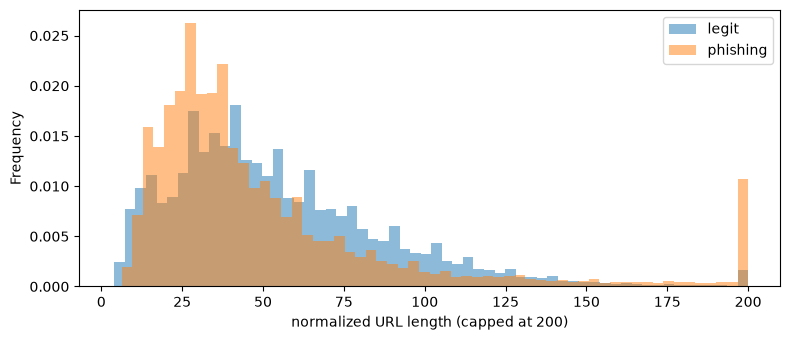

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, name in [(0, "legit"), (1, "phishing")]:
    stats.loc[data["is_phishing"] == label, "length"].clip(upper=200).plot.hist(
        bins=60, alpha=0.5, density=True, ax=ax, label=name)
ax.set_xlabel("normalized URL length (capped at 200)"); ax.legend(); plt.tight_layout(); plt.show()

### 4c. The leak detector
Train a small model on **only** those 8 shallow stats (length, slashes, has a query, and so on), with nothing about the actual words. Folds are grouped by domain, so no domain appears in both training and scoring.

- If this scores near 1.0, the classes are separable by collection artifacts and a deep model would learn those first. **Stop and fix the data.**
- A moderate score is fine. It's the bar the deep model in notebook 07 has to clearly beat to prove it learned something about the words.

In [8]:
%%time
groups = data["registered"].values
leak_model = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)
leak_p = cross_val_predict(leak_model, stats, data["is_phishing"], groups=groups,
                           cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
LEAK_PR_AUC = average_precision_score(data["is_phishing"], leak_p)
print(f"shallow-stats leak detector PR-AUC: {LEAK_PR_AUC:.3f}   (0.5 = no signal, 1.0 = fully separable)")
if LEAK_PR_AUC > 0.95:
    print("WARNING: the classes are almost separable by shape alone. Investigate before training.")

shallow-stats leak detector PR-AUC: 0.891   (0.5 = no signal, 1.0 = fully separable)
CPU times: user 26.2 s, sys: 9.58 s, total: 35.8 s
Wall time: 5.15 s


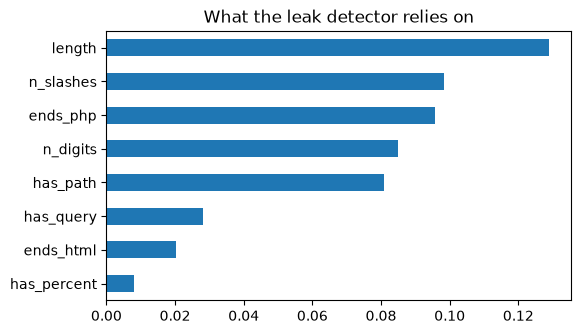

In [9]:
leak_model.fit(stats, data["is_phishing"])
from sklearn.inspection import permutation_importance
imp = permutation_importance(leak_model, stats, data["is_phishing"], n_repeats=3,
                             random_state=RANDOM_STATE, scoring="average_precision")
pd.Series(imp.importances_mean, index=stats.columns).sort_values().plot.barh(
    figsize=(6, 3.5), title="What the leak detector relies on"); plt.show()

### 4d. Domain-level checks
The deep model will see TLDs and hosting platforms. Here's how differently each class uses them.

In [10]:
parts = pd.DataFrame([split_host(u) for u in data["url"]])
tld = parts["suffix"].str.rsplit(".", n=1).str[-1]
top = (pd.crosstab(tld, data["is_phishing"].map({0: "legit", 1: "phishing"}), normalize="columns")
       .sort_values("phishing", ascending=False).head(12).round(3))
print(f"free-hosting share: legit {parts.loc[data.is_phishing == 0, 'platform'].mean():.1%}, "
      f"phishing {parts.loc[data.is_phishing == 1, 'platform'].mean():.1%}")
top

free-hosting share: legit 0.2%, phishing 30.4%


is_phishing,legit,phishing
suffix,,
com,0.519,0.373
io,0.016,0.065
org,0.052,0.053
dev,0.001,0.049
app,0.003,0.044
top,0.001,0.031
net,0.030,0.028
xyz,0.001,0.020
me,0.003,0.017


### 4e. Do the two legit sources look alike?
If sitemap URLs and Common Crawl URLs differ a lot in shape, the model could learn the mix of sources. Compare them with each other and with phishing.

In [11]:
stats.groupby(data["source"]).mean().round(3).T

source,commoncrawl,commoncrawl_home,phishing_db,sitemap
length,56.658,12.493,51.546,58.699
has_path,0.965,0.000,0.677,0.994
n_slashes,2.432,0.000,1.645,2.574
has_query,0.215,0.000,0.160,0.021
has_percent,0.049,0.000,0.022,0.014
ends_html,0.098,0.000,0.129,0.098
ends_php,0.040,0.000,0.188,0.011
n_digits,5.367,0.072,6.609,3.393


## 5. Look at examples
Read these. The eye catches leaks that statistics miss.

In [12]:
show = data.groupby("is_phishing").sample(10, random_state=1)[["text", "is_phishing"]].copy()
show.loc[show.is_phishing == 1, "text"] = show.loc[show.is_phishing == 1, "text"].map(lambda t: t.replace(".", "[.]"))
show

,text,is_phishing
55783,zebra.com/ru/ru/web-apps/tablet-selector.html,0
42959,05.ru/cat/03a568c6/p/chekhol-nakladka-deppa-dlya-samsung-galaxy-s21-biryuzovyy-10343/reviews,0
43760,fifa.com,0
48350,juspay.io/integrations/methods/the-nainital-bank,0
57812,expedient.com/2012/05/22,0
74140,arcade.ch/insights/blog/fibx,0
38764,app.synopanel.com/registration/social-media/extrapanel-belgium-french/fr/default,0
52213,ng88b.com/en-bd/tablegames,0
69436,tandem.net/pt-br/learn/chinese/babol,0
42935,harpersbazaar.com/fashion/trends/g65805849/nordstrom-handbag-sale-august-2025,0


## 6. Split by domain: train / validation / test
Every registered domain lands in exactly one split. A random row split would put `evil.top/a` in training and `evil.top/b` in test, and the model would look great by memorizing domains.

- **train** (80%): the model learns from this
- **validation** (10%): early stopping and tuning in notebook 07
- **test** (10%): touched once, at the end

The notebook 03 to 05 benchmark is still the real scoreboard. This test set only checks that training worked.

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr, rest = next(gss.split(data, groups=groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=RANDOM_STATE)
va, te = next(gss2.split(data.iloc[rest], groups=groups[rest]))
data["split"] = "train"
data.loc[data.index[rest[va]], "split"] = "val"
data.loc[data.index[rest[te]], "split"] = "test"

assert data.groupby("registered")["split"].nunique().max() == 1, "a domain is in two splits"
pd.crosstab(data["split"], data["is_phishing"].map({0: "legit", 1: "phishing"}), margins=True)

is_phishing,legit,phishing,All
split,,,
test,4037,3825,7862
train,30857,30715,61572
val,3409,3884,7293
All,38303,38424,76727


## 7. Save

In [14]:
out = PROJECT_ROOT / "data" / "processed"
out.mkdir(parents=True, exist_ok=True)
cols = ["text", "is_phishing", "registered", "source", "split"]
data[cols].to_csv(out / "fullurl_dataset.csv.gz", index=False)
summary_card = {
    "n_urls": len(data), "n_domains": int(data["registered"].nunique()),
    "phish_per_domain_cap": PHISH_PER_DOMAIN, "legit_per_domain_cap": LEGIT_PER_DOMAIN,
    "leak_detector_pr_auc": round(LEAK_PR_AUC, 4),
    "splits": data["split"].value_counts().to_dict(),
}
import json; (out / "fullurl_dataset.json").write_text(json.dumps(summary_card, indent=2))
print(f"saved data/processed/fullurl_dataset.csv.gz ({len(data):,} rows)")
summary_card

saved data/processed/fullurl_dataset.csv.gz (76,727 rows)


{'n_urls': 76727,
 'n_domains': 40605,
 'phish_per_domain_cap': 5,
 'legit_per_domain_cap': 15,
 'leak_detector_pr_auc': 0.8908,
 'splits': {'train': 61572, 'test': 7862, 'val': 7293}}

## Results log
Fill in after running.

- URLs / domains: 
- Raw differences that normalizing removed: 
- Differences that remain after normalizing (4b): 
- Leak detector PR-AUC: 
- What it relied on: 
- Anything suspicious in the examples: 

**Decision:** is the data clean enough to train on? If the leak detector is above about 0.95, fix the data first.